In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

import os
os.makedirs("images", exist_ok=True)

from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import f_regression

pd.set_option('display.max_columns', 200)
df = pd.read_csv('nigeria_inflation_clean.csv')
df.shape
#df.isna().sum()
df.describe()
#df.head(7)

,Year,Inflation_pct,GDP_growth_pct,Exchange_rate_NGN_per_USD,Broad_money_growth_pct,Brent_oil_USD
count,34.000000,34.000000,34.000000,34.000000,34.000000,34.000000
mean,2008.500000,19.333423,3.962206,248.846504,25.520071,55.372898
std,9.958246,15.960527,3.940890,345.866759,19.069707,31.721628
min,1992.000000,5.386104,-6.368898,17.298425,-0.794167,13.126219
25%,2000.250000,10.203818,1.994175,104.080812,14.253582,24.814096
50%,2008.500000,13.493038,4.212993,140.884012,20.044370,54.785382
75%,2016.750000,18.867032,6.406317,292.715582,34.151621,78.018458
max,2025.000000,72.835502,15.329156,1518.380948,87.761349,112.011673


Inflation_pct                2.09
GDP_growth_pct               0.02
Exchange_rate_NGN_per_USD    3.01
Broad_money_growth_pct       1.34
Brent_oil_USD                0.29
dtype: float64


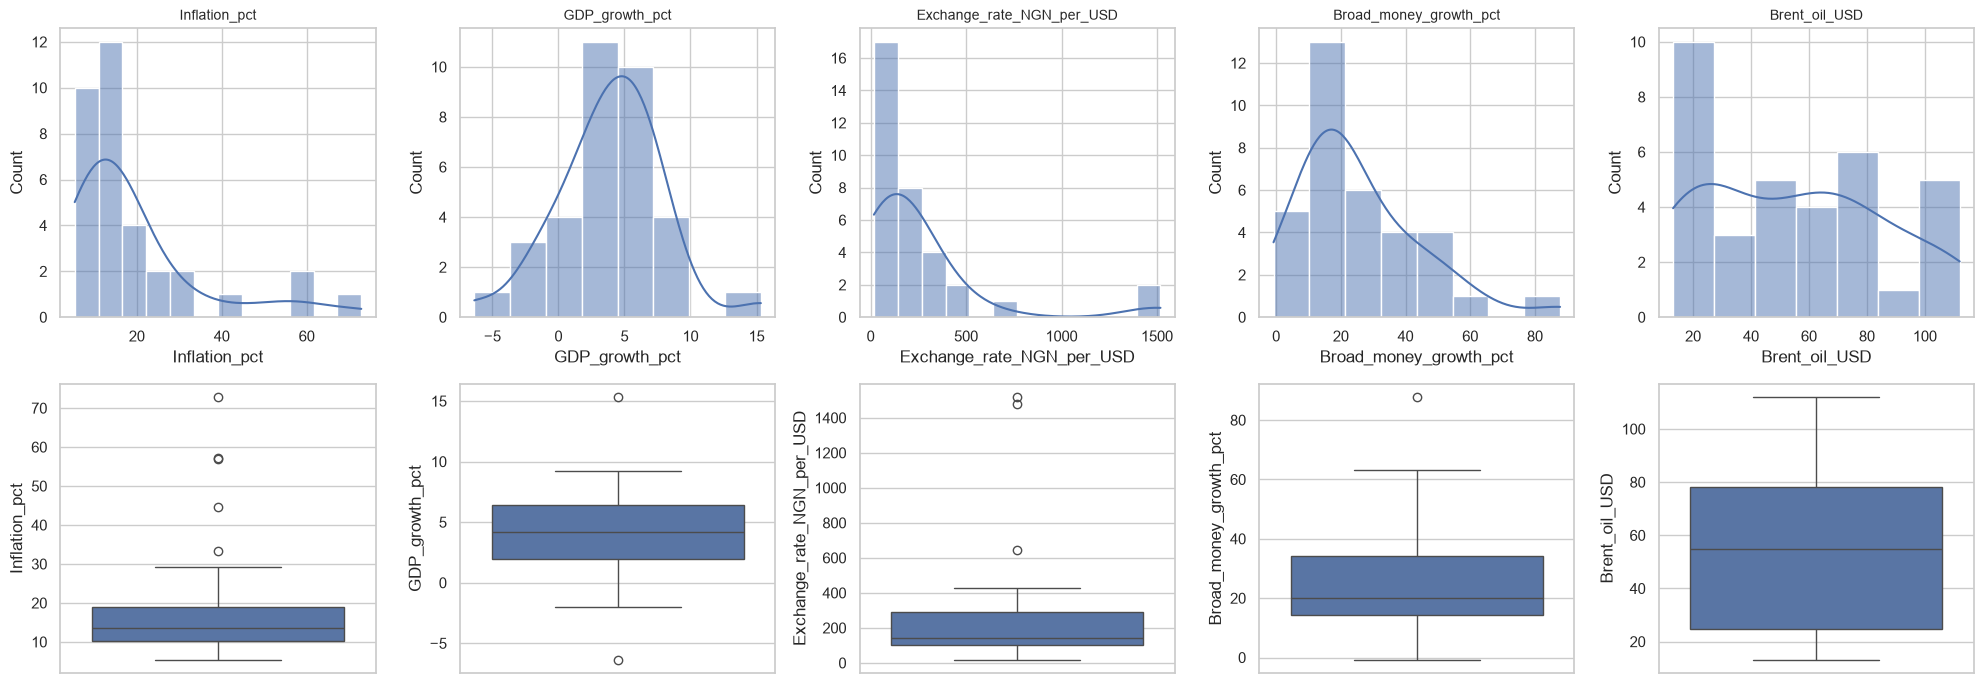

In [2]:
cols = ["Inflation_pct", "GDP_growth_pct", "Exchange_rate_NGN_per_USD",
        "Broad_money_growth_pct", "Brent_oil_USD"]

print(df[cols].skew().round(2))

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i])
    sns.boxplot(y=df[c], ax=axes[1, i])
    axes[0, i].set_title(c, fontsize=10)
plt.tight_layout()
plt.savefig("images/00_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

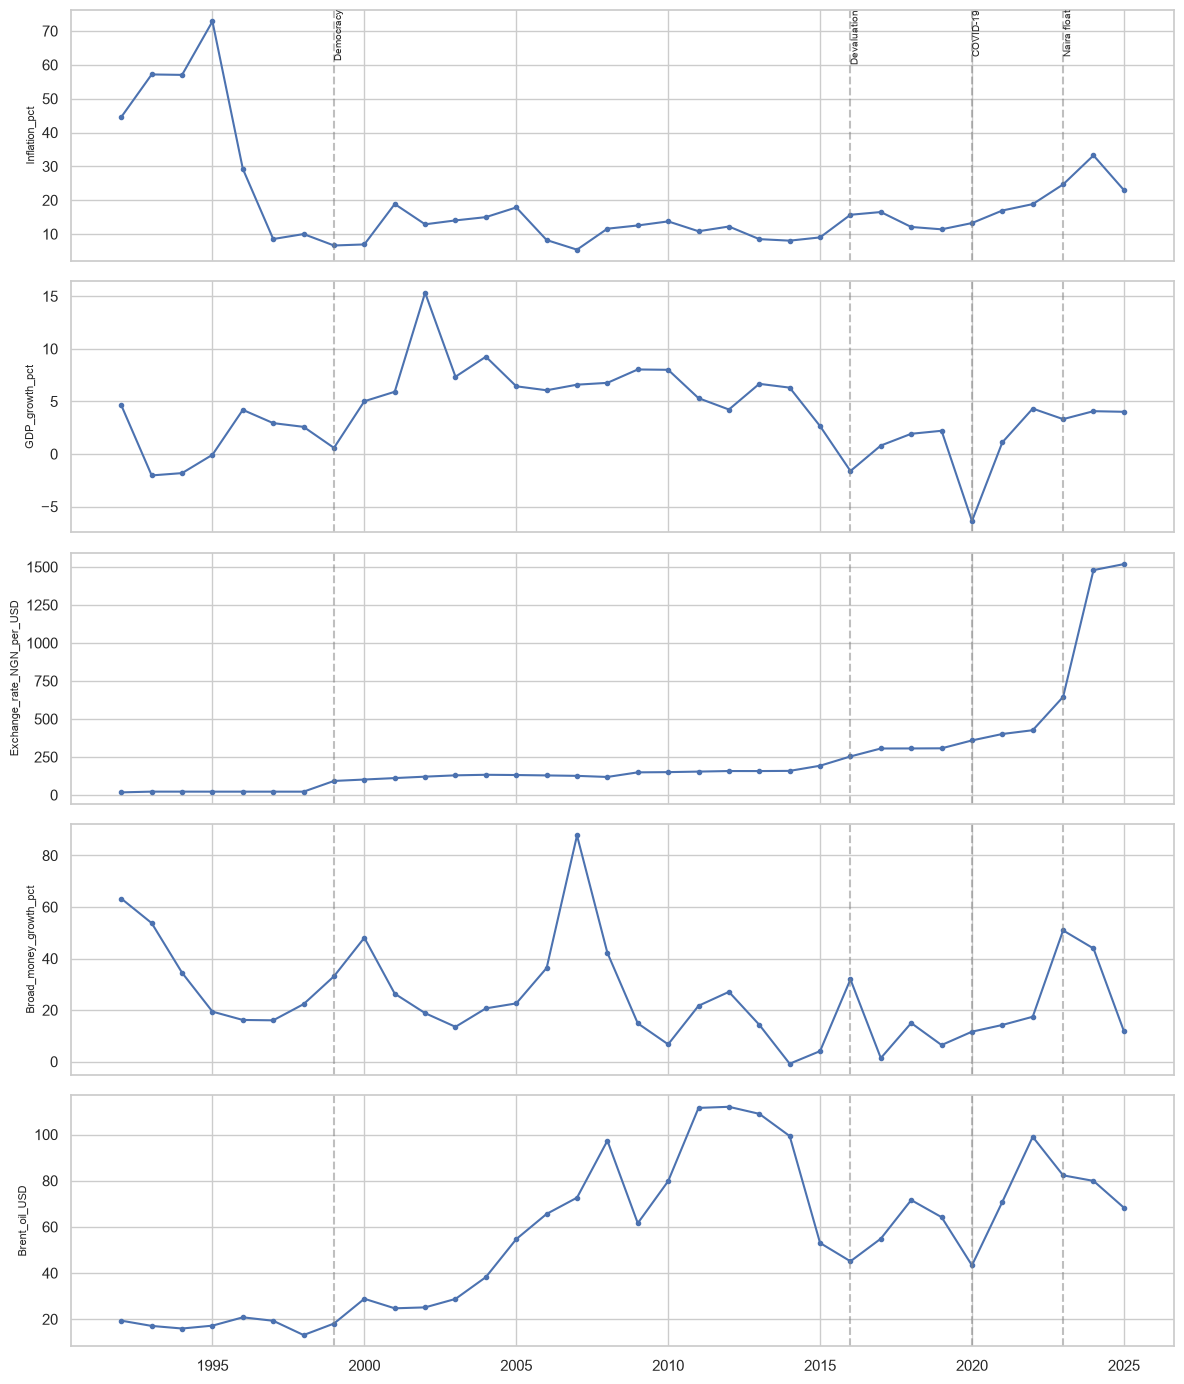

In [3]:
events = {1999: "Democracy", 2016: "Devaluation", 2020: "COVID-19", 2023: "Naira float"}

fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=True)
for ax, c in zip(axes, cols):
    ax.plot(df["Year"], df[c], marker="o", ms=3)
    ax.set_ylabel(c, fontsize=8)
    for yr in events:
        ax.axvline(yr, color="grey", ls="--", alpha=0.5)
for yr, label in events.items():
    axes[0].text(yr, axes[0].get_ylim()[1], label, rotation=90, va="top", fontsize=7)
plt.tight_layout()
plt.savefig("images/01_time_series.png", dpi=150, bbox_inches="tight")
plt.show()

Exchange_rate_NGN_per_USD    3.01
Log_exchange_rate           -0.12
Exchange_rate_change_pct     4.53
dtype: float64
Exchange_rate_NGN_per_USD    0.02
Log_exchange_rate           -0.40
Exchange_rate_change_pct    -0.05
Inflation_pct                1.00
Name: Inflation_pct, dtype: float64


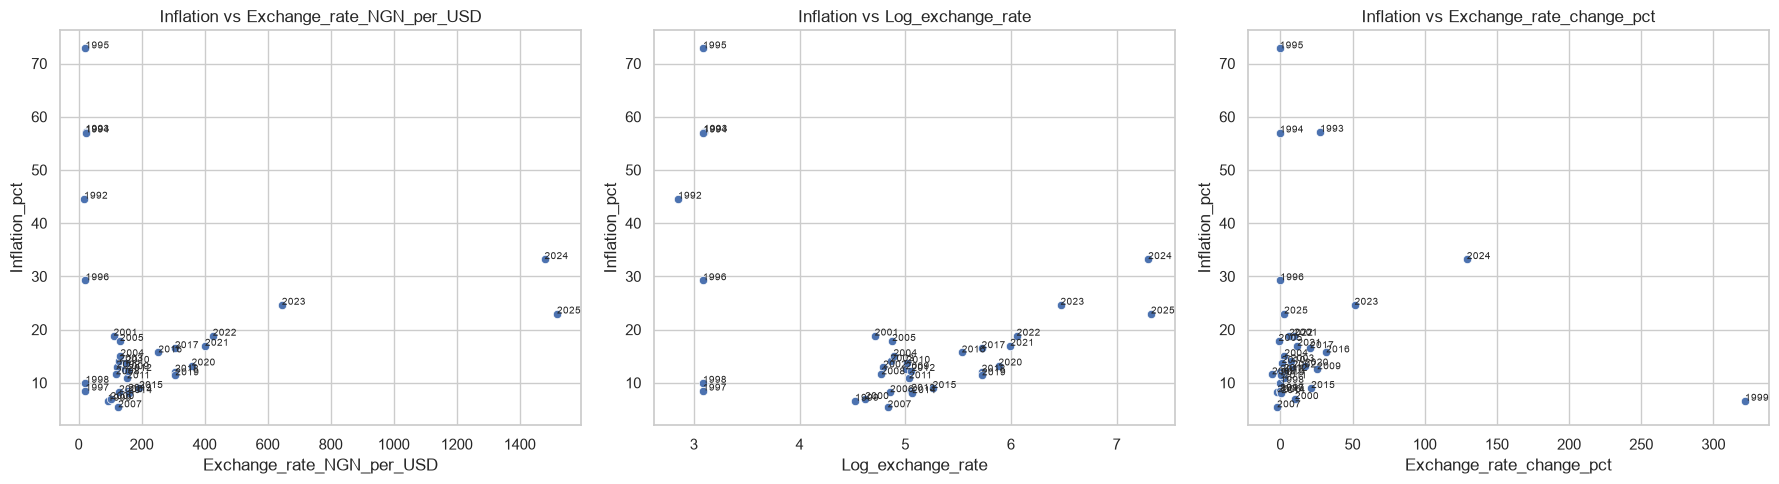

In [4]:
df["Log_exchange_rate"] = np.log(df["Exchange_rate_NGN_per_USD"])
df["Exchange_rate_change_pct"] = df["Exchange_rate_NGN_per_USD"].pct_change() * 100

ex_cols = ["Exchange_rate_NGN_per_USD", "Log_exchange_rate", "Exchange_rate_change_pct"]
print(df[ex_cols].skew().round(2))
print(df[ex_cols + ["Inflation_pct"]].corr()["Inflation_pct"].round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, c in zip(axes, ex_cols):
    sns.scatterplot(x=df[c], y=df["Inflation_pct"], ax=ax)
    for _, r in df.iterrows():
        ax.annotate(int(r["Year"]), (r[c], r["Inflation_pct"]), fontsize=7)
    ax.set_title(f"Inflation vs {c}")
plt.tight_layout()
plt.savefig("images/02_exchange_rate_transforms.png", dpi=150, bbox_inches="tight")
plt.show()

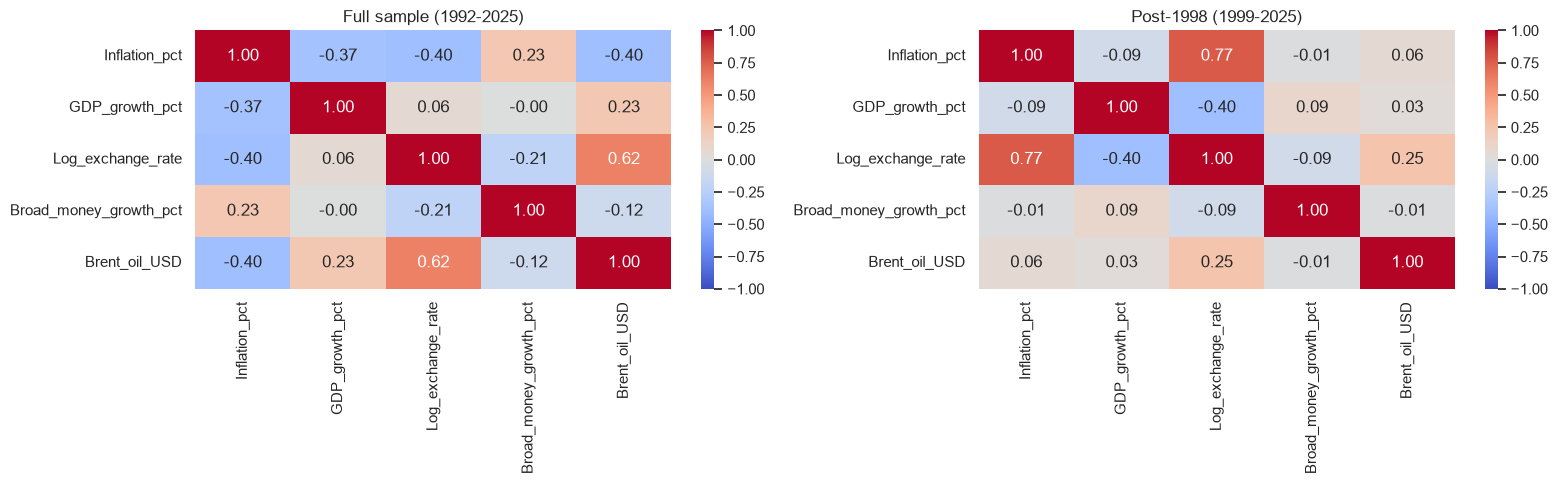

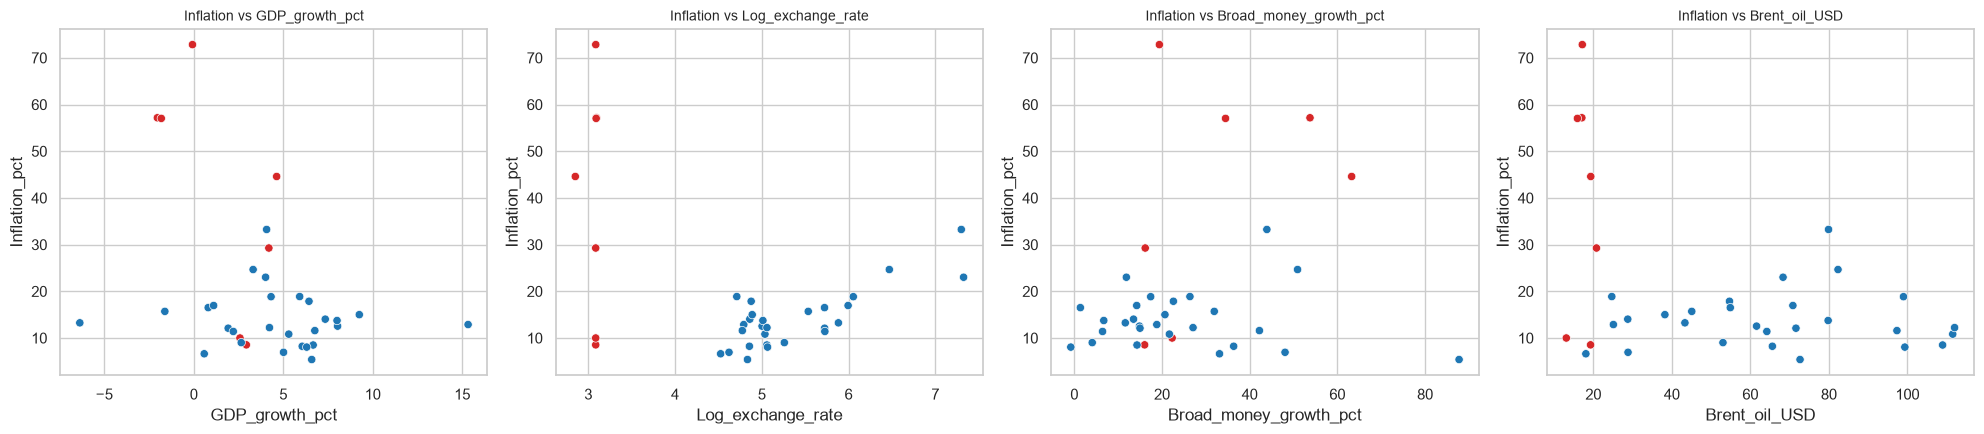

In [5]:
analysis_cols = ["Inflation_pct", "GDP_growth_pct", "Log_exchange_rate",
                 "Broad_money_growth_pct", "Brent_oil_USD"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(df[analysis_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Full sample (1992-2025)")
sns.heatmap(df[df["Year"] >= 1999][analysis_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Post-1998 (1999-2025)")
plt.tight_layout()
plt.show()

predictors = analysis_cols[1:]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, c in zip(axes, predictors):
    sns.scatterplot(x=df[c], y=df["Inflation_pct"], hue=(df["Year"] >= 1999),
                    palette={False: "tab:red", True: "tab:blue"}, legend=False, ax=ax)
    ax.set_title(f"Inflation vs {c}", fontsize=10)
plt.tight_layout()
plt.savefig("images/03_correlation_heatmaps.png", dpi=150, bbox_inches="tight")
plt.savefig("images/04_regime_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
import statsmodels.formula.api as smf

formula = "Inflation_pct ~ GDP_growth_pct + Log_exchange_rate + Broad_money_growth_pct + Brent_oil_USD"
post_df = df[df["Year"] >= 1999]

full = smf.ols(formula, data=df).fit()
post = smf.ols(formula, data=post_df).fit()

print(post.summary())   # main model first

comp = pd.DataFrame({
    "coef_full": full.params, "p_full": full.pvalues,
    "coef_post": post.params, "p_post": post.pvalues,
}).round(4)
print(comp)
print(f"Full:  F={full.fvalue:.2f}, p={full.f_pvalue:.4f}, adj R2={full.rsquared_adj:.3f}")
print(f"Post:  F={post.fvalue:.2f}, p={post.f_pvalue:.4f}, adj R2={post.rsquared_adj:.3f}")

# single-predictor models: F-statistic for each variable on its own
rows = []
for c in predictors:
    for label, d in [("Full", df), ("Post-1998", post_df)]:
        m = smf.ols(f"Inflation_pct ~ {c}", data=d).fit()
        rows.append([c, label, m.fvalue, m.f_pvalue, m.rsquared])
print(pd.DataFrame(rows, columns=["Predictor", "Sample", "F", "p_value", "R2"]).round(4))

                            OLS Regression Results                            
Dep. Variable:          Inflation_pct   R-squared:                       0.687
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     12.09
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           2.39e-05
Time:                        07:45:03   Log-Likelihood:                -71.135
No. Observations:                  27   AIC:                             152.3
Df Residuals:                      22   BIC:                             158.7
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                -26

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm

# 1. Multicollinearity (VIF above ~5 to 10 is a concern)
X = sm.add_constant(post_df[predictors])
vif = pd.DataFrame({"variable": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
print(vif.round(2))

# 2. Partial F-test: do the 3 extra predictors add anything beyond log exchange rate?
restricted = smf.ols("Inflation_pct ~ Log_exchange_rate", data=post_df).fit()
print(anova_lm(restricted, post))

# 3. Robust standard errors (HC3) vs normal ones
robust = smf.ols(formula, data=post_df).fit(cov_type="HC3")
print(pd.DataFrame({"p_normal": post.pvalues, "p_HC3": robust.pvalues}).round(4))

# 4. Most influential years (Cook's distance)
cooks = pd.Series(post.get_influence().cooks_distance[0], index=post_df["Year"].values)
print(cooks.sort_values(ascending=False).head(5).round(3))

# 5. Does the result survive without 2023-2025?
sens = smf.ols(formula, data=post_df[post_df["Year"] <= 2022]).fit()
print(sens.summary().tables[1])

                 variable    VIF
0                   const  76.95
1          GDP_growth_pct   1.22
2       Log_exchange_rate   1.30
3  Broad_money_growth_pct   1.01
4           Brent_oil_USD   1.09
   df_resid         ssr  df_diff    ss_diff         F    Pr(>F)
0      25.0  394.937568      0.0        NaN       NaN       NaN
1      22.0  307.105107      3.0  87.832461  2.097343  0.129677
                        p_normal   p_HC3
Intercept                 0.0003  0.0148
GDP_growth_pct            0.0432  0.0450
Log_exchange_rate         0.0000  0.0002
Broad_money_growth_pct    0.7057  0.8617
Brent_oil_USD             0.1471  0.1501
2007    0.950
2025    0.375
2024    0.373
2002    0.168
2001    0.143
dtype: float64
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                -14.6645     12.933     -1.134      0.271     -41.733      12.404
GDP_gr

In [8]:
# 1. Refit without 2007 (the most influential year)
no2007 = smf.ols(formula, data=post_df[post_df["Year"] != 2007]).fit()
print(no2007.summary().tables[1])

# 2. Full sample with a regime dummy (1 = 1992-1998)
df["Pre1999"] = (df["Year"] <= 1998).astype(int)
dummy = smf.ols(formula + " + Pre1999", data=df).fit()
print(dummy.summary().tables[1])
print(f"F={dummy.fvalue:.2f}, p={dummy.f_pvalue:.4f}, adj R2={dummy.rsquared_adj:.3f}")

# 3. One-year lagged predictors (does last year's value matter more?)
for c in predictors:
    df[c + "_lag1"] = df[c].shift(1)
lag_formula = "Inflation_pct ~ " + " + ".join(c + "_lag1" for c in predictors)
lag = smf.ols(lag_formula, data=df[df["Year"] >= 2000]).fit()
print(lag.summary().tables[1])
print(f"Lagged: F={lag.fvalue:.2f}, p={lag.f_pvalue:.4f}, adj R2={lag.rsquared_adj:.3f}")

# 4. Model comparison: simple vs full (post-1998)
simple = smf.ols("Inflation_pct ~ Log_exchange_rate", data=post_df).fit()
print(pd.DataFrame({
    "model": ["Exchange rate only", "All four predictors"],
    "adj_R2": [simple.rsquared_adj, post.rsquared_adj],
    "AIC": [simple.aic, post.aic],
    "BIC": [simple.bic, post.bic],
}).round(3))

                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                -27.1170      5.670     -4.783      0.000     -38.908     -15.326
GDP_growth_pct             0.4334      0.182      2.375      0.027       0.054       0.813
Log_exchange_rate          7.3666      1.008      7.306      0.000       5.270       9.463
Broad_money_growth_pct     0.0934      0.047      1.989      0.060      -0.004       0.191
Brent_oil_USD             -0.0341      0.025     -1.388      0.180      -0.085       0.017
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                -18.9681     19.707     -0.963      0.344     -59.336      21.400
GDP_growth_pct            -0.2965      0.603     -0.491      0.627      -1.532       0.939

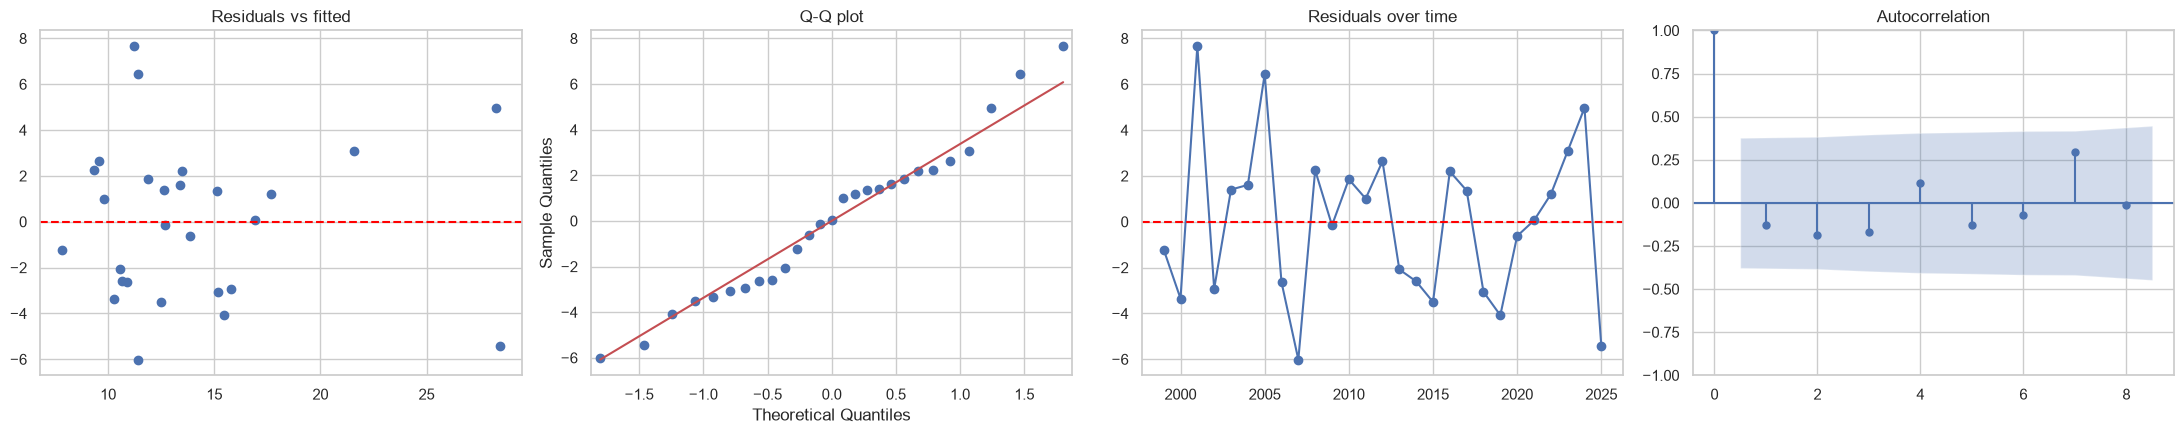

Breusch-Pagan p-value: 0.2455
                        std_beta      p
GDP_growth_pct             0.282  0.043
Log_exchange_rate          0.937  0.000
Broad_money_growth_pct     0.046  0.706
Brent_oil_USD             -0.187  0.147
                predictor      F       p
0          GDP_growth_pct   0.21  0.6482
1       Log_exchange_rate  37.17  0.0000
2  Broad_money_growth_pct   0.01  0.9426
3           Brent_oil_USD   0.08  0.7842
Baseline (predict the training mean): RMSE 10.86
Exchange rate only: test RMSE 6.48, R2 0.13
All four: test RMSE 6.65, R2 0.08


In [9]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.metrics import mean_squared_error, r2_score

# 1. Residual diagnostics for the post-1998 model
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
axes[0].scatter(post.fittedvalues, post.resid)
axes[0].axhline(0, color="red", ls="--"); axes[0].set_title("Residuals vs fitted")
sm.qqplot(post.resid, line="s", ax=axes[1]); axes[1].set_title("Q-Q plot")
axes[2].plot(post_df["Year"], post.resid, marker="o")
axes[2].axhline(0, color="red", ls="--"); axes[2].set_title("Residuals over time")
plot_acf(post.resid, lags=8, ax=axes[3])
plt.tight_layout(); 
plt.savefig("images/05_residual_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

bp = het_breuschpagan(post.resid, post.model.exog)
print("Breusch-Pagan p-value:", round(bp[1], 4))

# 2. Standardized coefficients (rank predictors on a common scale)
z = post_df[["Inflation_pct"] + predictors].apply(lambda s: (s - s.mean()) / s.std())
std = smf.ols("Inflation_pct ~ " + " + ".join(predictors), data=z).fit()
print(pd.DataFrame({"std_beta": std.params, "p": std.pvalues}).drop("Intercept").round(3))

# 3. sklearn cross-check of the single-predictor F-statistics
F, p = f_regression(post_df[predictors], post_df["Inflation_pct"])
print(pd.DataFrame({"predictor": predictors, "F": F.round(2), "p": p.round(4)}))

# 4. Time-ordered train/test split (train 1999-2018, test 2019-2025)
train, test = post_df[post_df["Year"] <= 2018], post_df[post_df["Year"] > 2018]
y_tr, y_te = train["Inflation_pct"], test["Inflation_pct"]
base_rmse = np.sqrt(mean_squared_error(y_te, np.full(len(y_te), y_tr.mean())))
print(f"Baseline (predict the training mean): RMSE {base_rmse:.2f}")
for name, cols in [("Exchange rate only", ["Log_exchange_rate"]), ("All four", predictors)]:
    m = LinearRegression().fit(train[cols], y_tr)
    pred = m.predict(test[cols])
    print(f"{name}: test RMSE {np.sqrt(mean_squared_error(y_te, pred)):.2f}, "
          f"R2 {r2_score(y_te, pred):.2f}")